Mounted at /content/drive
📂 Loading saved data...
✅ Loaded y_test shape: (141123, 24, 1)
✅ Loaded Predictions shape: (141123, 24, 1)


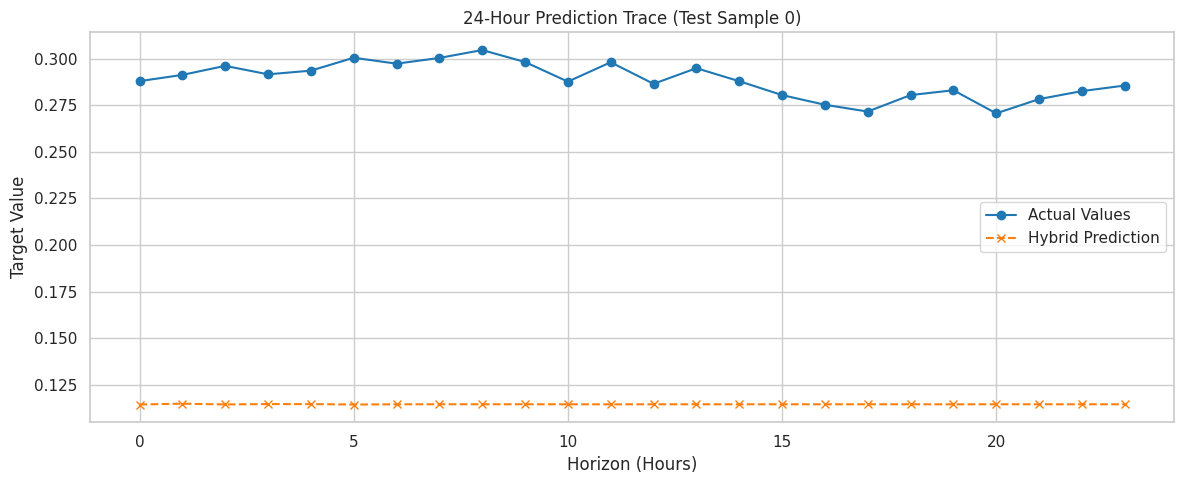

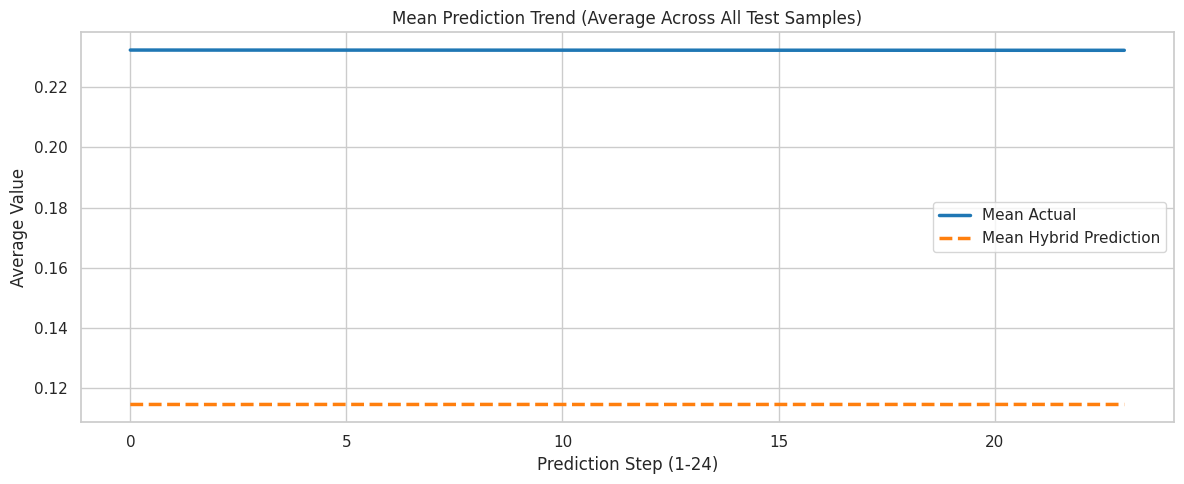

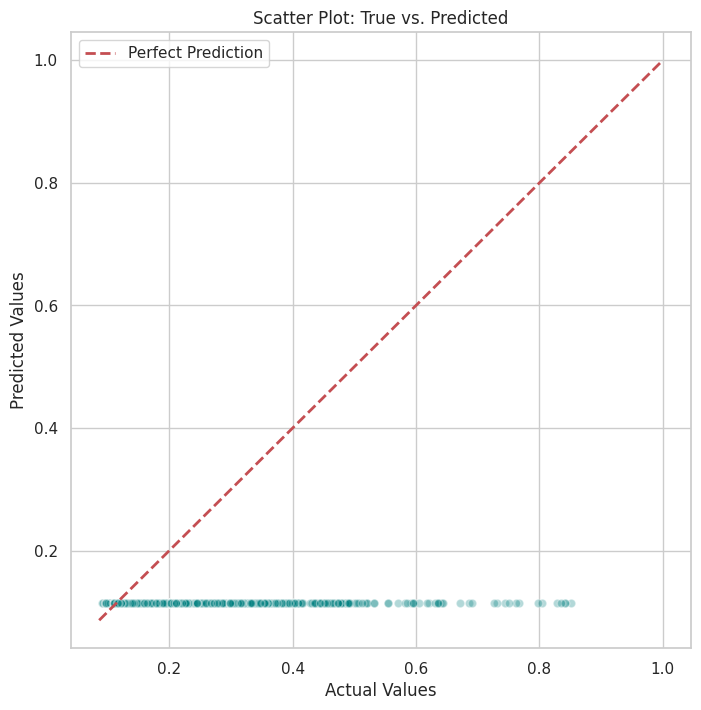

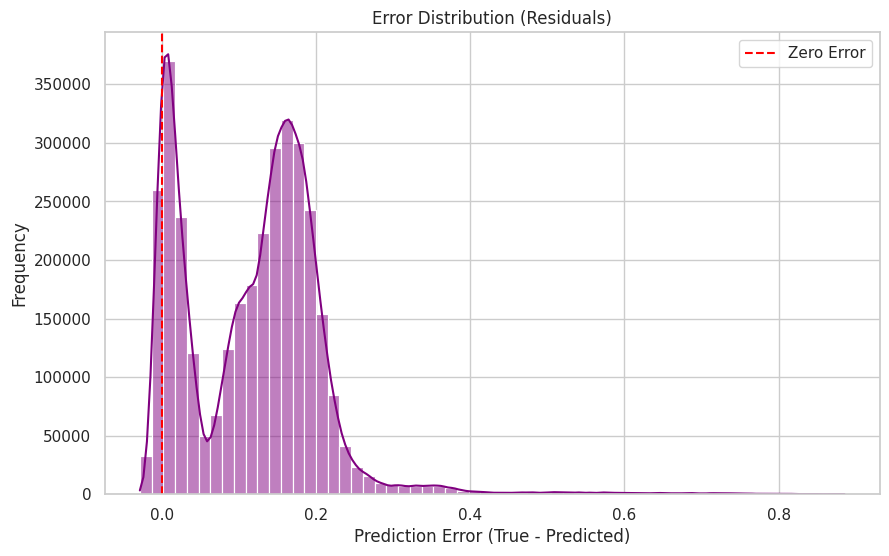

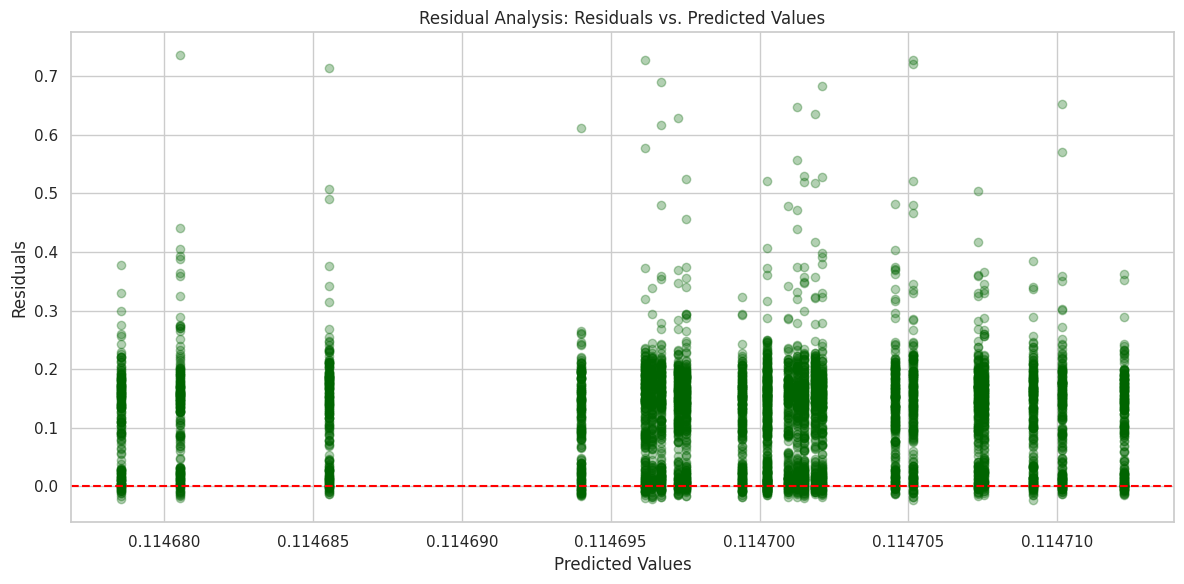

✨ All graphs generated successfully from saved drive files!


In [ ]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from google.colab import drive

# 1. Mount Drive
drive.mount('/content/drive')

# 2. Paths and Loading
SAVE_DIR = '/content/drive/MyDrive/Datasets/Models_Final_V5'

print("📂 Loading saved data...")
# Ground Truth
y_test = np.load(os.path.join(SAVE_DIR, 'y_test.npy'))
# Hybrid Model Predictions
final_hybrid_pred = np.load(os.path.join(SAVE_DIR, 'hybrid_arima_final_pred.npy'))

print(f"✅ Loaded y_test shape: {y_test.shape}")
print(f"✅ Loaded Predictions shape: {final_hybrid_pred.shape}")

# 3. Data Preparation
# Flatten for global metrics (Scatter, Histogram, Residuals)
y_true_flat = y_test.flatten()
y_pred_flat = final_hybrid_pred.flatten()
residuals = y_true_flat - y_pred_flat

# Set global plotting style
sns.set_theme(style="whitegrid")
plt.rcParams.update({'font.size': 12})

# ==========================================
# 1. 24-Hour Prediction Trace
# ==========================================
plt.figure(figsize=(12, 5))
sample_idx = 0 # You can change this index to see different test windows
plt.plot(y_test[sample_idx].flatten(), label='Actual Values', marker='o', color='#1f77b4')
plt.plot(final_hybrid_pred[sample_idx].flatten(), label='Hybrid Prediction', marker='x', linestyle='--', color='#ff7f0e')
plt.title(f"24-Hour Prediction Trace (Test Sample {sample_idx})")
plt.xlabel("Horizon (Hours)")
plt.ylabel("Target Value")
plt.legend()
plt.tight_layout()
plt.show()

# ==========================================
# 2. Mean Prediction Across All Test Samples
# ==========================================
plt.figure(figsize=(12, 5))
# Average the values for each of the 24 steps across all test samples
mean_true = np.mean(y_test, axis=0).flatten()
mean_pred = np.mean(final_hybrid_pred, axis=0).flatten()

plt.plot(mean_true, label='Mean Actual', linewidth=2.5, color='#1f77b4')
plt.plot(mean_pred, label='Mean Hybrid Prediction', linewidth=2.5, linestyle='--', color='#ff7f0e')
plt.title("Mean Prediction Trend (Average Across All Test Samples)")
plt.xlabel("Prediction Step (1-24)")
plt.ylabel("Average Value")
plt.legend()
plt.tight_layout()
plt.show()

# ==========================================
# 3. Scatter Plot (True vs Predicted)
# ==========================================
plt.figure(figsize=(8, 8))
# Sample 5000 points to keep the plot clean and fast
sample_size = min(5000, len(y_true_flat))
idx = np.random.choice(len(y_true_flat), sample_size, replace=False)

plt.scatter(y_true_flat[idx], y_pred_flat[idx], alpha=0.3, color='teal', edgecolors='w')
# Perfect prediction line (y=x)
min_val = min(y_true_flat.min(), y_pred_flat.min())
max_val = max(y_true_flat.max(), y_pred_flat.max())
plt.plot([min_val, max_val], [min_val, max_val], 'r--', lw=2, label='Perfect Prediction')

plt.title("Scatter Plot: True vs. Predicted")
plt.xlabel("Actual Values")
plt.ylabel("Predicted Values")
plt.legend()
plt.show()

# ==========================================
# 4. Error Distribution Histogram
# ==========================================
plt.figure(figsize=(10, 6))
sns.histplot(residuals, kde=True, color='purple', bins=60)
plt.axvline(x=0, color='red', linestyle='--', label='Zero Error')
plt.title("Error Distribution (Residuals)")
plt.xlabel("Prediction Error (True - Predicted)")
plt.ylabel("Frequency")
plt.legend()
plt.show()

# ==========================================
# 5. Residual Analysis (Residuals vs. Predicted)
# ==========================================
plt.figure(figsize=(12, 6))
plt.scatter(y_pred_flat[idx], residuals[idx], alpha=0.3, color='darkgreen')
plt.axhline(y=0, color='red', linestyle='--')
plt.title("Residual Analysis: Residuals vs. Predicted Values")
plt.xlabel("Predicted Values")
plt.ylabel("Residuals")
plt.tight_layout()
plt.show()

print("✨ All graphs generated successfully from saved drive files!")